In [2]:
import numpy as np
import pandas as pd

In [4]:
#Load the data
df=pd.read_csv("BlinkIT Grocery Data.csv")

In [6]:
df.head()

,Item Fat Content,Item Identifier,Item Type,Outlet Establishment Year,Outlet Identifier,Outlet Location Type,Outlet Size,Outlet Type,Item Visibility,Item Weight,Total Sales,Rating
0,Regular,FDX32,Fruits and Vegetables,2012,OUT049,Tier 1,Medium,Supermarket Type1,0.100014,15.10,145.4786,5.0
1,Low Fat,NCB42,Health and Hygiene,2022,OUT018,Tier 3,Medium,Supermarket Type2,0.008596,11.80,115.3492,5.0
2,Regular,FDR28,Frozen Foods,2010,OUT046,Tier 1,Small,Supermarket Type1,0.025896,13.85,165.0210,5.0
3,Regular,FDL50,Canned,2000,OUT013,Tier 3,High,Supermarket Type1,0.042278,12.15,126.5046,5.0
4,Low Fat,DRI25,Soft Drinks,2015,OUT045,Tier 2,Small,Supermarket Type1,0.033970,19.60,55.1614,5.0


In [8]:
df.shape

(8523, 12)

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item Fat Content           8523 non-null   object 
 1   Item Identifier            8523 non-null   object 
 2   Item Type                  8523 non-null   object 
 3   Outlet Establishment Year  8523 non-null   int64  
 4   Outlet Identifier          8523 non-null   object 
 5   Outlet Location Type       8523 non-null   object 
 6   Outlet Size                8523 non-null   object 
 7   Outlet Type                8523 non-null   object 
 8   Item Visibility            8523 non-null   float64
 9   Item Weight                7060 non-null   float64
 10  Total Sales                8523 non-null   float64
 11  Rating                     8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB


In [14]:
#check exact missing data
df.isnull().sum()

Item Fat Content                0
Item Identifier                 0
Item Type                       0
Outlet Establishment Year       0
Outlet Identifier               0
Outlet Location Type            0
Outlet Size                     0
Outlet Type                     0
Item Visibility                 0
Item Weight                  1463
Total Sales                     0
Rating                          0
dtype: int64

In [16]:
# Check duplicate rows
df.duplicated().sum()

np.int64(0)

In [26]:
# Statistical summary
df.describe()

,Outlet Establishment Year,Item Visibility,Item Weight,Total Sales,Rating
count,8523.000000,8523.000000,7060.000000,8523.000000,8523.000000
mean,2010.831867,0.066132,12.857645,140.992782,3.965857
std,8.371760,0.051598,4.643456,62.275067,0.605651
min,1998.000000,0.000000,4.555000,31.290000,1.000000
25%,2000.000000,0.026989,8.773750,93.826500,4.000000
50%,2012.000000,0.053931,12.600000,143.012800,4.000000
75%,2017.000000,0.094585,16.850000,185.643700,4.200000
max,2022.000000,0.328391,21.350000,266.888400,5.000000


In [38]:
#identify the numerical data
df.select_dtypes(include='number').columns

Index(['Outlet Establishment Year', 'Item Visibility', 'Item Weight',
       'Total Sales', 'Rating'],
      dtype='object')

In [40]:
#identify the categorical data
df.select_dtypes(include='object').columns

Index(['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Identifier',
       'Outlet Location Type', 'Outlet Size', 'Outlet Type'],
      dtype='object')

In [42]:
#check unique data
df.nunique

<bound method DataFrame.nunique of      Item Fat Content Item Identifier              Item Type  \
0             Regular           FDX32  Fruits and Vegetables   
1             Low Fat           NCB42     Health and Hygiene   
2             Regular           FDR28           Frozen Foods   
3             Regular           FDL50                 Canned   
4             Low Fat           DRI25            Soft Drinks   
...               ...             ...                    ...   
8518          low fat           NCT53     Health and Hygiene   
8519          low fat           FDN09            Snack Foods   
8520          low fat           DRE13            Soft Drinks   
8521              reg           FDT50                  Dairy   
8522              reg           FDM58            Snack Foods   

      Outlet Establishment Year Outlet Identifier Outlet Location Type  \
0                          2012            OUT049               Tier 1   
1                          2022            OUT01

In [44]:
#check the co-relation of data
df.corr(numeric_only=True)

,Outlet Establishment Year,Item Visibility,Item Weight,Total Sales,Rating
Outlet Establishment Year,1.000000,-0.074834,-0.011588,0.005020,0.004489
Item Visibility,-0.074834,1.000000,-0.014048,-0.001315,0.000798
Item Weight,-0.011588,-0.014048,1.000000,0.027141,0.002711
Total Sales,0.005020,-0.001315,0.027141,1.000000,0.011329
Rating,0.004489,0.000798,0.002711,0.011329,1.000000


In [46]:
import seaborn as sns
import matplotlib.pyplot as plt

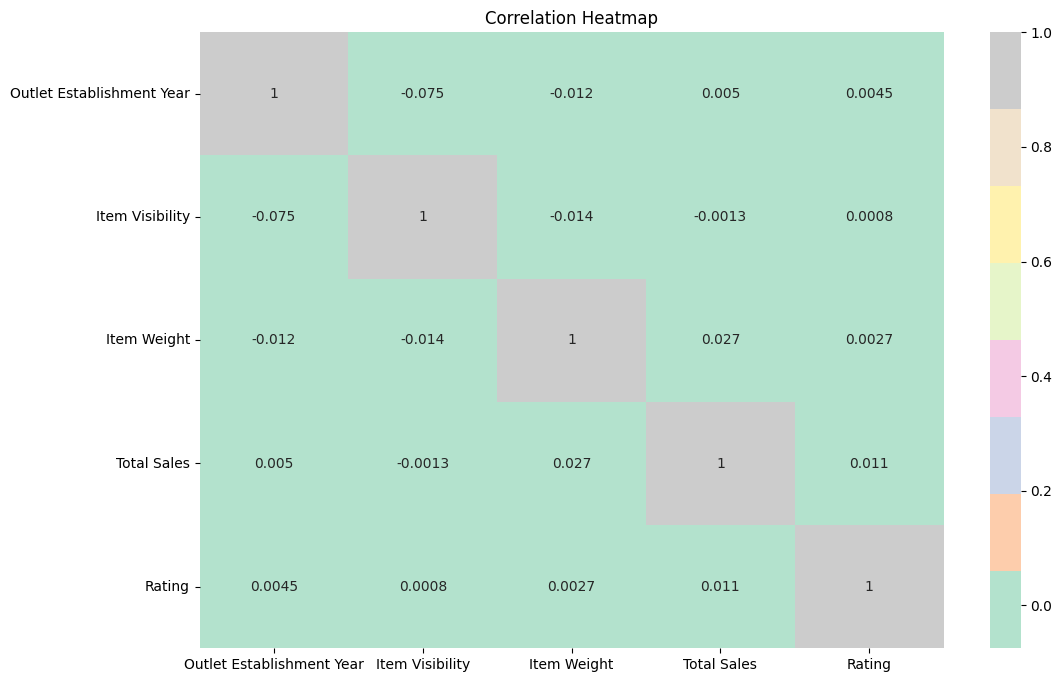

In [65]:
#check co-relation by heatmap
plt.figure(figsize=(12, 8))
sns.heatmap(df.corr(numeric_only=True), annot=True, cmap="Pastel2")
plt.title("Correlation Heatmap")
plt.show()

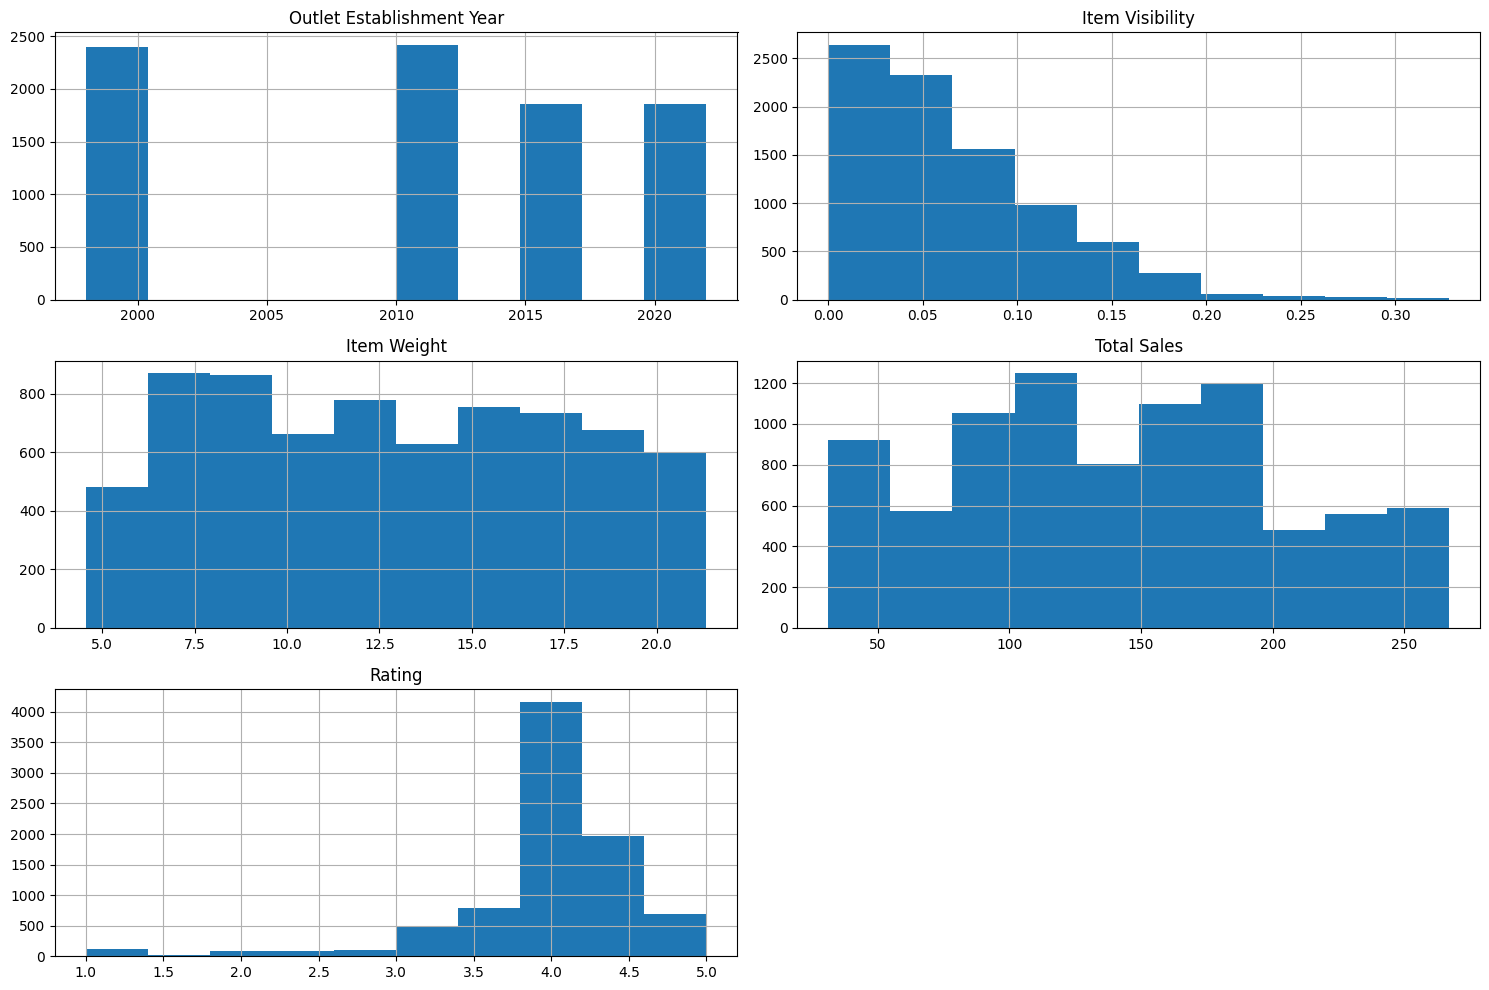

In [66]:
#Distribution of Numerical Data
df.hist(figsize=(15, 10))
plt.tight_layout()
plt.show()

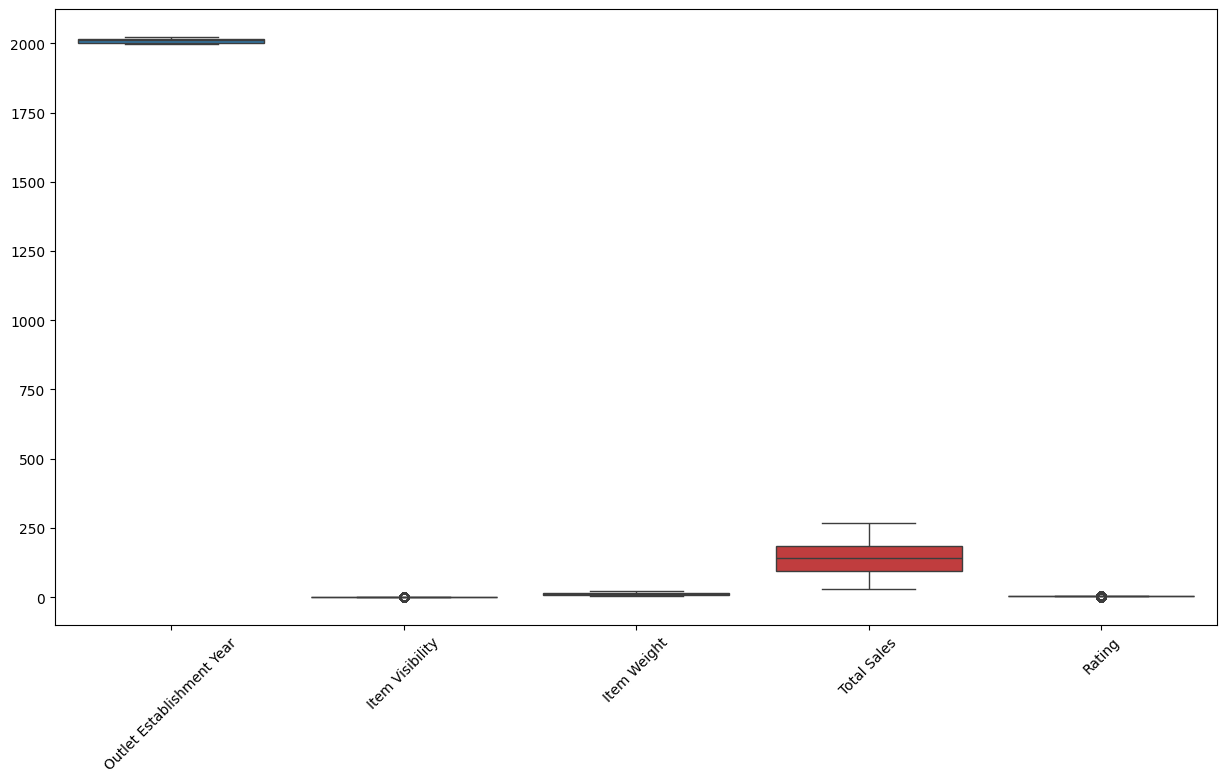

In [68]:
#check the outlier
plt.figure(figsize=(15, 8))
sns.boxplot(data=df.select_dtypes(include='number'))
plt.xticks(rotation=45)
plt.show()

In [70]:
#Check the value Distribution of Categorical data
for col in df.select_dtypes(include='object').columns:
    print(f"\n{col}")
    print(df[col].value_counts())


Item Fat Content
Item Fat Content
Low Fat    5089
Regular    2889
LF          316
reg         117
low fat     112
Name: count, dtype: int64

Item Identifier
Item Identifier
FDW13    10
FDG33    10
FDF56     9
FDF52     9
FDV38     9
         ..
FDK57     1
FDO33     1
DRF48     1
FDC23     1
FDE52     1
Name: count, Length: 1559, dtype: int64

Item Type
Item Type
Fruits and Vegetables    1232
Snack Foods              1200
Household                 910
Frozen Foods              856
Dairy                     682
Canned                    649
Baking Goods              648
Health and Hygiene        520
Soft Drinks               445
Meat                      425
Breads                    251
Hard Drinks               214
Others                    169
Starchy Foods             148
Breakfast                 110
Seafood                    64
Name: count, dtype: int64

Outlet Identifier
Outlet Identifier
OUT027    935
OUT013    932
OUT049    930
OUT046    930
OUT035    930
OUT045    929
OUT018

In [72]:
#beafore the the apply of the missing data
df.isnull().sum().sum()

np.int64(1463)

In [77]:
#apply to drop of missing data
df = df.dropna()

In [79]:
#check the after applying the missing data
df.isnull().sum().sum()

np.int64(0)

In [81]:
df.shape

(7060, 12)

In [83]:
df.to_csv("geldium_cleaned.csv", index=False)

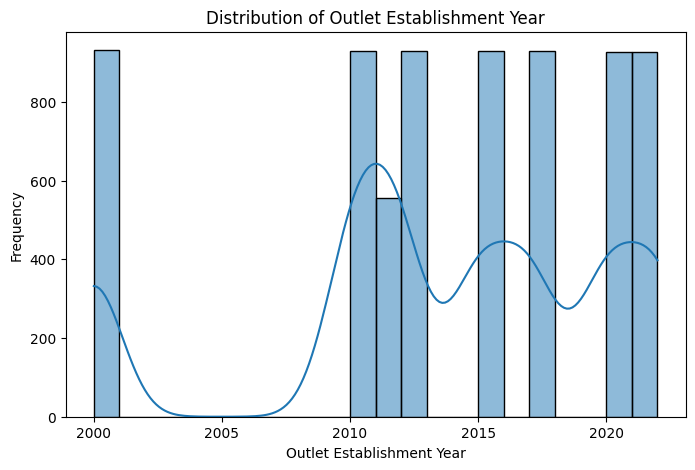

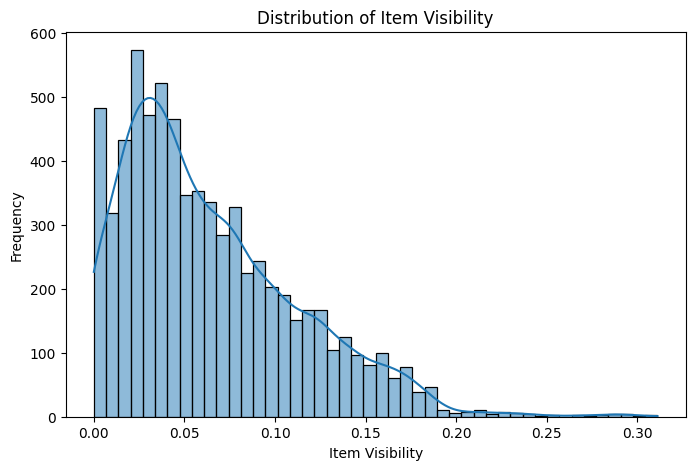

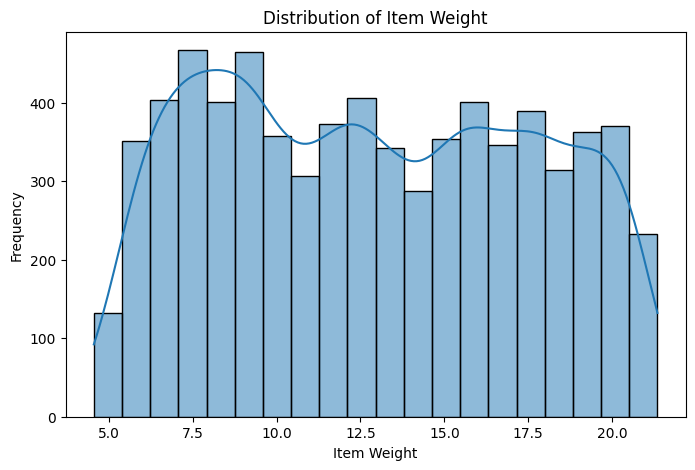

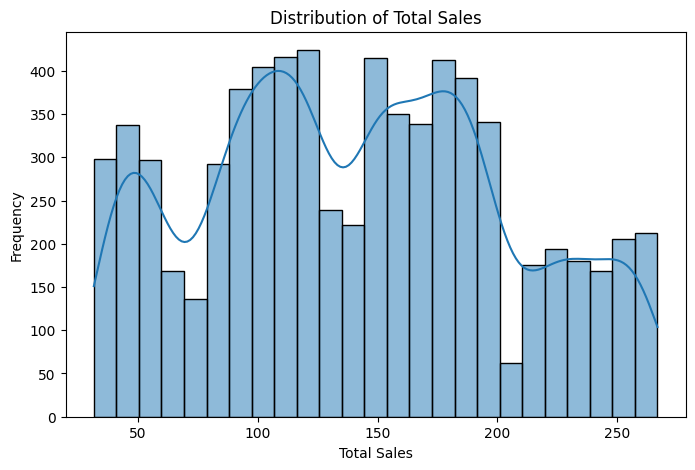

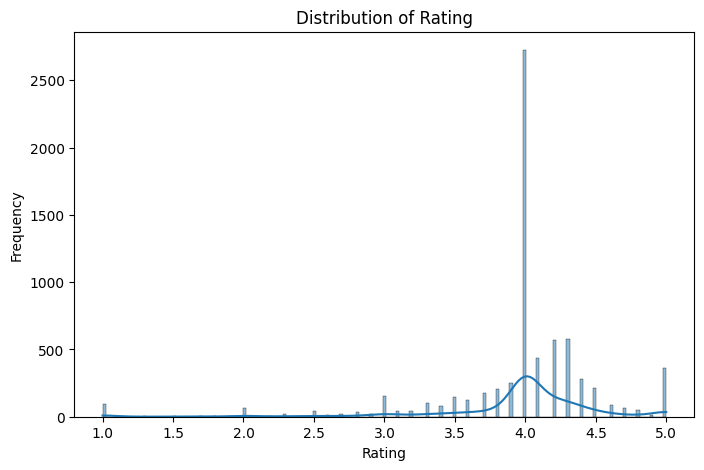

In [85]:
#EDA Nuerical data
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    plt.figure(figsize=(8, 5))
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")
    plt.show()

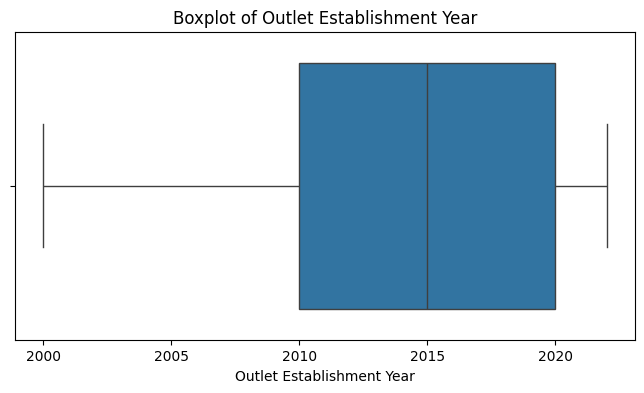

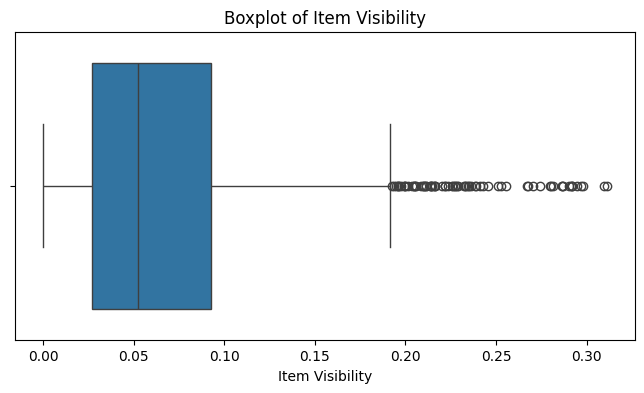

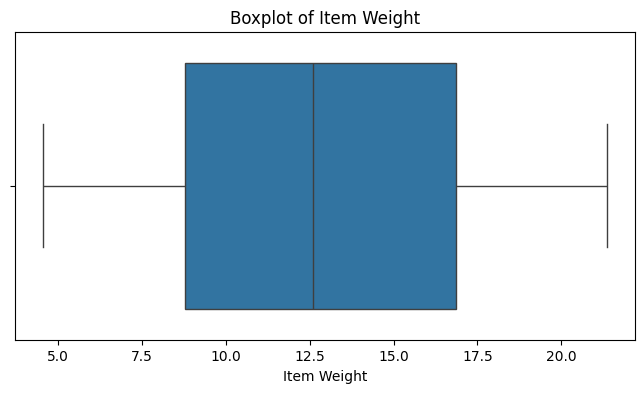

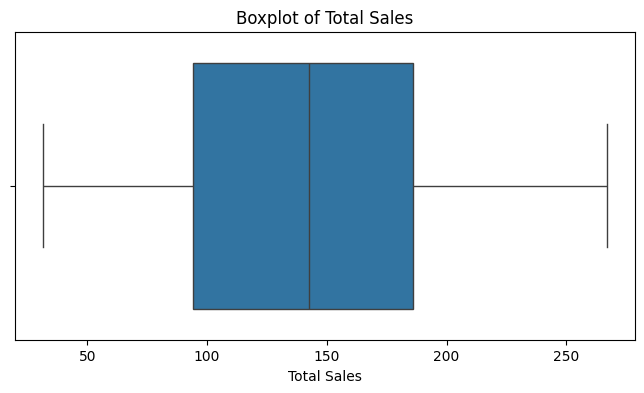

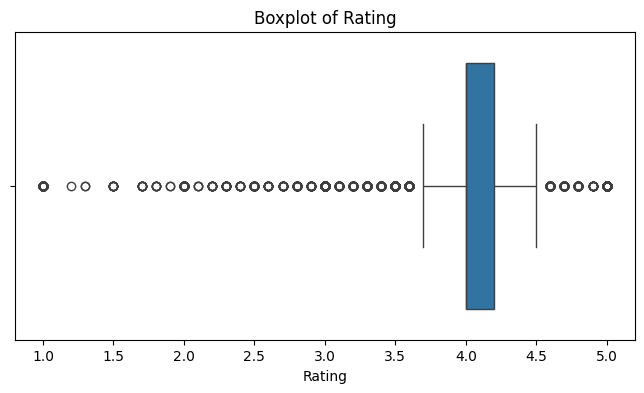

In [87]:
#Boxplot Analysis
numeric_cols = df.select_dtypes(include="number").columns

for col in numeric_cols:
    plt.figure(figsize=(8, 4))
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")
    plt.show()

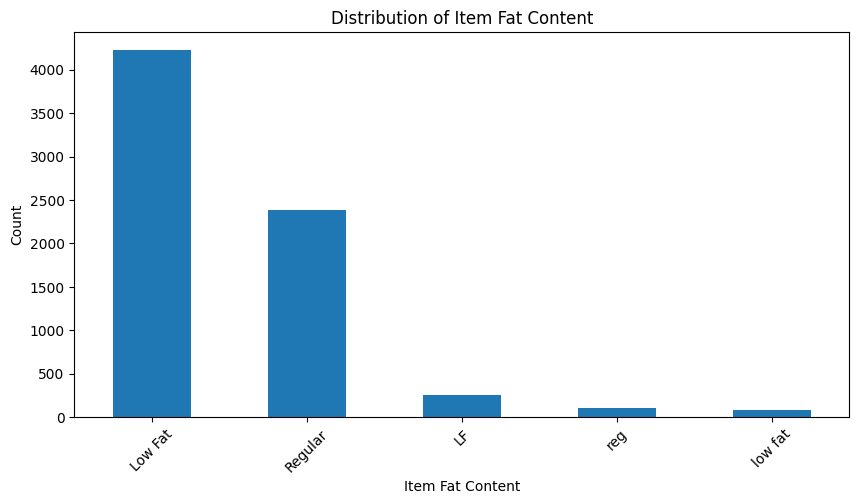

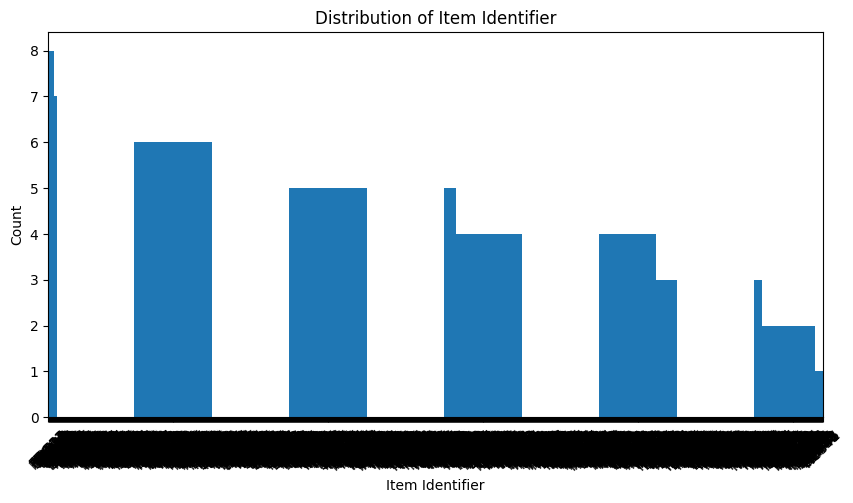

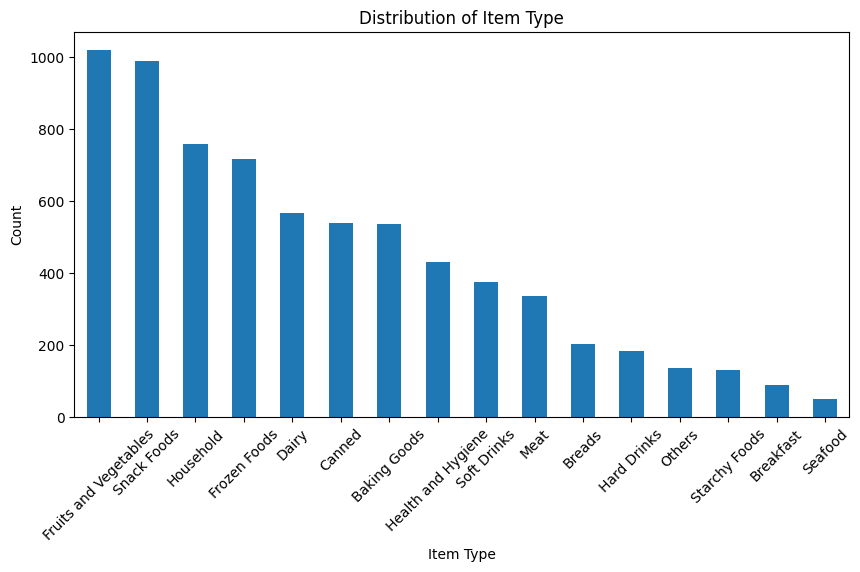

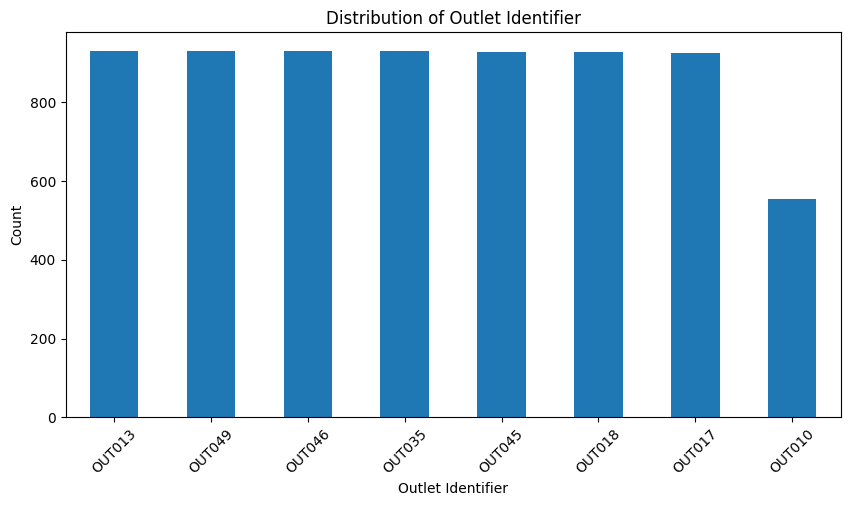

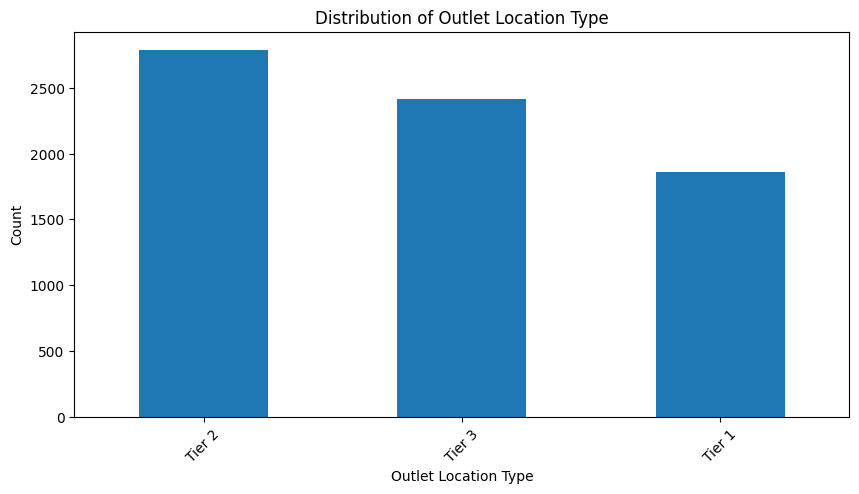

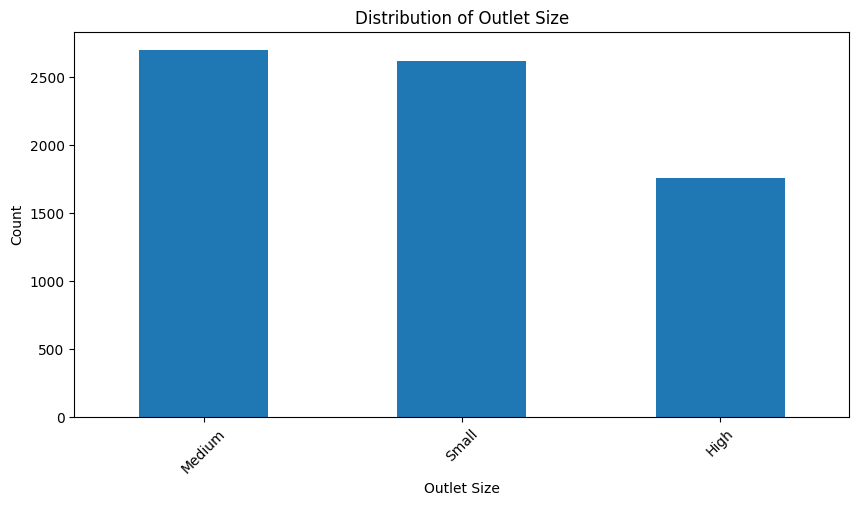

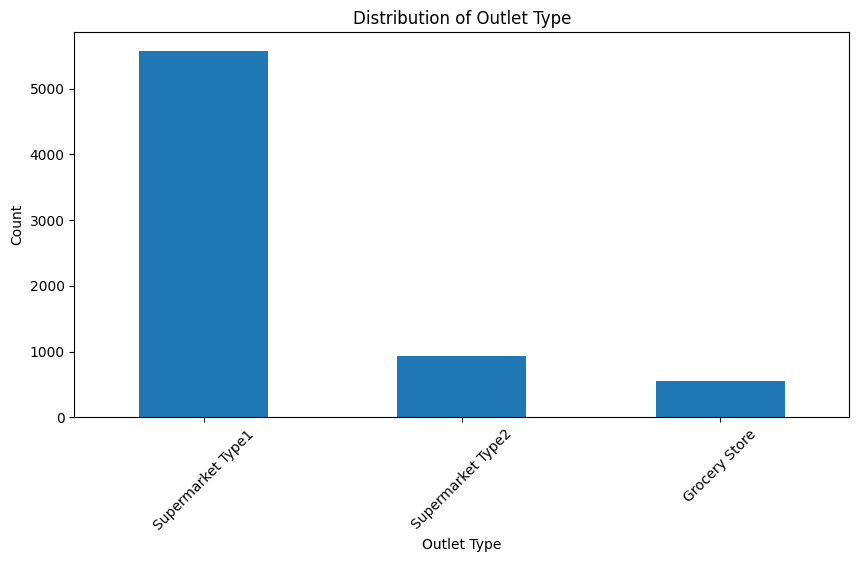

In [101]:
#categoorical analysis
categorical_cols = df.select_dtypes(include="object").columns

for col in categorical_cols:
    plt.figure(figsize=(10, 5))
    df[col].value_counts().plot(kind="bar")
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()

In [103]:
corr

,Outlet Establishment Year,Item Visibility,Item Weight,Total Sales,Rating
Outlet Establishment Year,1.000000,-0.016935,-0.011588,-0.001657,0.008659
Item Visibility,-0.016935,1.000000,-0.014048,-0.006061,-0.002384
Item Weight,-0.011588,-0.014048,1.000000,0.027141,0.002711
Total Sales,-0.001657,-0.006061,0.027141,1.000000,0.009186
Rating,0.008659,-0.002384,0.002711,0.009186,1.000000


In [105]:
#co-relation analysis
corr = df.select_dtypes(include="number").corr()

In [109]:
df.columns.tolist()

['Item Fat Content',
 'Item Identifier',
 'Item Type',
 'Outlet Establishment Year',
 'Outlet Identifier',
 'Outlet Location Type',
 'Outlet Size',
 'Outlet Type',
 'Item Visibility',
 'Item Weight',
 'Total Sales',
 'Rating']

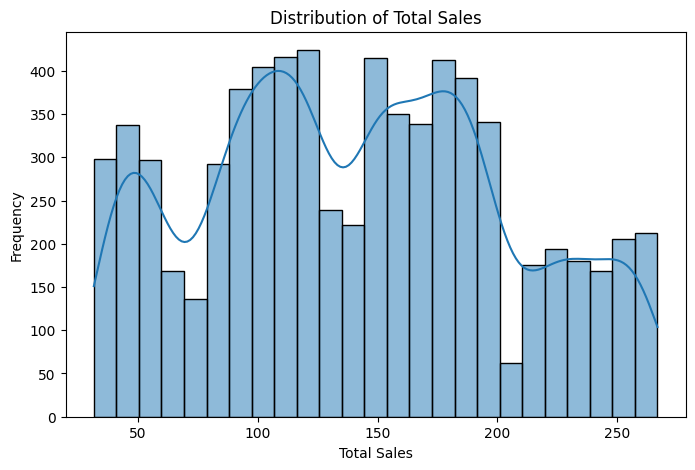

In [111]:
#Sales Ditribution Analysis
plt.figure(figsize=(8, 5))

sns.histplot(data=df, x="Total Sales", kde=True)

plt.title("Distribution of Total Sales")
plt.xlabel("Total Sales")
plt.ylabel("Frequency")
plt.show()

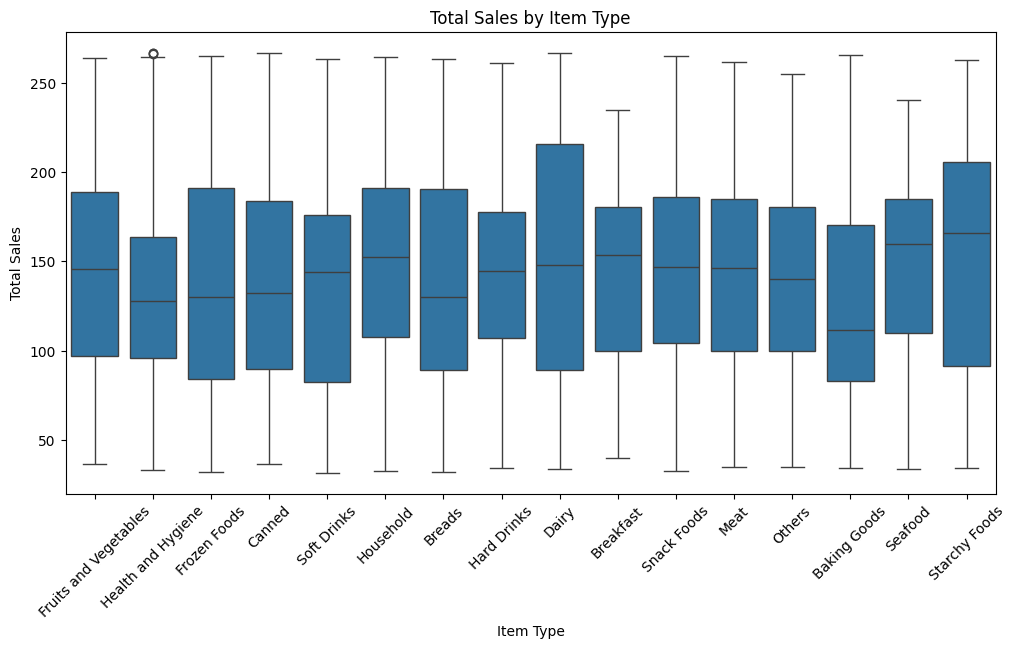

In [112]:
#Sales vs Item Check
plt.figure(figsize=(12, 6))

sns.boxplot(data=df, x="Item Type", y="Total Sales")

plt.title("Total Sales by Item Type")
plt.xlabel("Item Type")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.show()

In [114]:
X = df.drop("Total Sales", axis=1)
y = df["Total Sales"]

In [116]:
#Seprate Numeric and Categorical data
numeric_features = X.select_dtypes(include="number").columns
categorical_features = X.select_dtypes(include="object").columns

print("Numerical:", list(numeric_features))
print("Categorical:", list(categorical_features))

Numerical: ['Outlet Establishment Year', 'Item Visibility', 'Item Weight', 'Rating']
Categorical: ['Item Fat Content', 'Item Identifier', 'Item Type', 'Outlet Identifier', 'Outlet Location Type', 'Outlet Size', 'Outlet Type']


In [118]:
# train/test/split
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [123]:
#preprocessing the data
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)])

In [125]:
#Build the Baseline Model
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

In [127]:
#train the model 
model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [129]:
y_pred = model.predict(X_test)

y_pred[:10]

array([108.28134268,  75.50915151, 157.04422948, 143.5373605 ,
       100.01308507, 171.7248532 , 109.59255235,  93.12110005,
        73.6310985 , 119.98597148])

In [131]:
#evaluate the model
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 1.4662277481466084
RMSE: 5.59012034257358
R²  : 0.9921312875522075


In [133]:
#actual data vs predicted data
comparison = pd.DataFrame({
    "Actual Sales": y_test.values,
    "Predicted Sales": y_pred
})

comparison.head(10)

,Actual Sales,Predicted Sales
0,108.9938,108.281343
1,72.9696,75.509152
2,155.1288,157.044229
3,142.4812,143.537360
4,101.0016,100.013085
5,172.3448,171.724853
6,112.0228,109.592552
7,93.6462,93.121100
8,74.6354,73.631098
9,120.3440,119.985971


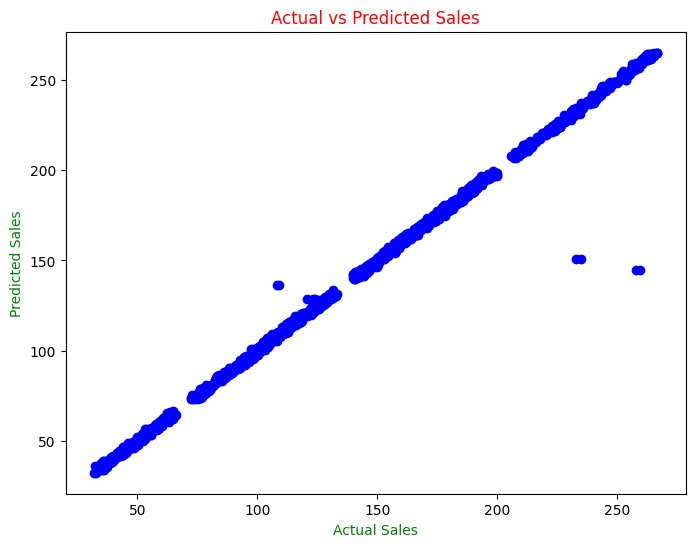

In [146]:
#actual vs predicted plot
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred,color="blue")

plt.xlabel("Actual Sales",color="green")
plt.ylabel("Predicted Sales",color="green")
plt.title("Actual vs Predicted Sales",color="red")

plt.show()

In [149]:
#try to fit best model
from sklearn.ensemble import RandomForestRegressor

rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        n_jobs=-1
    ))
])

In [151]:
#train random forest
rf_model.fit(X_train, y_train)

,steps,"[('preprocessor', ...), ('regressor', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [153]:
rf_pred = rf_model.predict(X_test)

rf_pred[:10]

array([148.614672, 101.787046, 143.720038, 142.123972, 133.144424,
       168.7045  , 114.21002 , 115.794776, 104.91375 , 123.560004])

In [155]:
rf_mae = mean_absolute_error(y_test, rf_pred)
rf_rmse = np.sqrt(mean_squared_error(y_test, rf_pred))
rf_r2 = r2_score(y_test, rf_pred)

print("Random Forest MAE :", rf_mae)
print("Random Forest RMSE:", rf_rmse)
print("Random Forest R²  :", rf_r2)

Random Forest MAE : 15.537728719546742
Random Forest RMSE: 22.070879391383567
Random Forest R²  : 0.8773406567088146


In [158]:
#compare the model
results = pd.DataFrame({
    "Model": ["Linear Regression", "Random Forest"],
    "MAE": [mae, rf_mae],
    "RMSE": [rmse, rf_rmse],
    "R2": [r2, rf_r2]
})

results

,Model,MAE,RMSE,R2
0,Linear Regression,1.466228,5.590120,0.992131
1,Random Forest,15.537729,22.070879,0.877341


In [170]:
best_model_name = results.loc[results["R2"].idxmax(), "Model"]

print("Best Model:", best_model_name)

Best Model: Linear Regression


In [173]:
#sales of outlet type
df.groupby("Outlet Type")["Total Sales"].mean().sort_values(ascending=False)

Outlet Type
Supermarket Type2    141.678634
Supermarket Type1    141.213894
Grocery Store        140.777594
Name: Total Sales, dtype: float64

In [175]:
#sales of outlet location
df.groupby("Outlet Location Type")["Total Sales"].mean().sort_values(ascending=False)

Outlet Location Type
Tier 3    141.374059
Tier 1    141.177543
Tier 2    141.167196
Name: Total Sales, dtype: float64

In [177]:
#Sales by outlet type
df.groupby("Item Type")["Total Sales"].mean().sort_values(ascending=False)

Item Type
Dairy                    149.340097
Household                149.156972
Starchy Foods            147.692132
Snack Foods              146.709644
Seafood                  145.050282
Fruits and Vegetables    144.444517
Breakfast                142.653791
Breads                   140.505808
Meat                     139.940359
Canned                   139.244894
Frozen Foods             139.222677
Hard Drinks              138.041625
Others                   135.945964
Soft Drinks              131.803935
Health and Hygiene       131.125121
Baking Goods             126.097226
Name: Total Sales, dtype: float64

In [180]:
#sales by outlet size
df.groupby("Outlet Size")["Total Sales"].mean().sort_values(ascending=False)

Outlet Size
Small     142.086015
High      142.037412
Medium    139.903952
Name: Total Sales, dtype: float64

In [182]:
#Sales by Eastablished Year
df.groupby("Outlet Establishment Year")["Total Sales"].mean().sort_values(ascending=False)

Outlet Establishment Year
2017    143.122481
2010    142.057387
2022    141.678634
2000    141.425982
2015    140.950246
2011    140.777594
2012    140.297699
2020    139.421119
Name: Total Sales, dtype: float64

In [184]:
#Rating by Total sales
df.groupby("Rating")["Total Sales"].mean().sort_values(ascending=False)

Rating
1.2    223.540400
1.5    179.287050
2.4    161.206825
2.5    156.981060
2.7    154.414358
4.6    152.473768
1.8    150.696080
3.4    149.650979
3.7    147.846559
2.2    147.753000
4.9    144.913917
4.4    144.912742
4.5    143.888640
3.5    142.965665
4.0    142.702473
3.6    142.374263
3.9    142.093484
2.6    141.013700
2.3    140.725333
4.7    140.555826
3.2    139.946600
4.2    139.483083
3.0    139.440324
5.0    139.185763
4.3    137.844257
3.1    137.838890
2.0    137.254678
4.8    136.711035
3.8    136.539838
4.1    136.482961
3.3    134.739099
2.9    134.231860
2.8    134.195200
1.3    133.075800
1.0    128.216052
1.7    120.538000
2.1    112.109667
1.9     53.165300
Name: Total Sales, dtype: float64

In [186]:
#Final Businees Summary
business_summary = {
    "Top Outlet Type": df.groupby("Outlet Type")["Total Sales"].mean().idxmax(),
    "Top Location Type": df.groupby("Outlet Location Type")["Total Sales"].mean().idxmax(),
    "Top Item Type": df.groupby("Item Type")["Total Sales"].mean().idxmax(),
    "Top Outlet Size": df.groupby("Outlet Size")["Total Sales"].mean().idxmax(),
    "Top Fat Content": df.groupby("Item Fat Content")["Total Sales"].mean().idxmax(),
    "Best Establishment Year": df.groupby("Outlet Establishment Year")["Total Sales"].mean().idxmax()
}

business_summary

{'Top Outlet Type': 'Supermarket Type2',
 'Top Location Type': 'Tier 3',
 'Top Item Type': 'Dairy',
 'Top Outlet Size': 'Small',
 'Top Fat Content': 'Regular',
 'Best Establishment Year': np.int64(2017)}

In [188]:
#Final Project Conclusion
print("Project Conclusion")
print("-" * 50)

print(f"Best performing outlet type: {business_summary['Top Outlet Type']}")
print(f"Best performing location type: {business_summary['Top Location Type']}")
print(f"Top performing item type: {business_summary['Top Item Type']}")
print(f"Best performing outlet size: {business_summary['Top Outlet Size']}")
print(f"Best performing fat content: {business_summary['Top Fat Content']}")
print(f"Best establishment year: {business_summary['Best Establishment Year']}")

print("\nBest ML Model: Linear Regression")
print(f"R² Score: {r2:.3f}")
print(f"MAE: {mae:.3f}")
print(f"RMSE: {rmse:.3f}")

Project Conclusion
--------------------------------------------------
Best performing outlet type: Supermarket Type2
Best performing location type: Tier 3
Top performing item type: Dairy
Best performing outlet size: Small
Best performing fat content: Regular
Best establishment year: 2017

Best ML Model: Linear Regression
R² Score: 0.992
MAE: 1.466
RMSE: 5.590


## Key Business Insights

1. Outlet performance varies across different outlet types and location types.
2. Some item categories generate significantly higher average sales than others.
3. Outlet size has an impact on average sales performance.
4. Item fat content shows differences in average sales.
5. Outlet establishment year helps identify changes in sales performance over time.
6. The Linear Regression model achieved the strongest performance among the tested models, with an R² score of approximately 0.992.

## Business Recommendations

1. Focus inventory and marketing efforts on high-performing item categories.
2. Prioritize outlet types and locations that consistently generate higher average sales.
3. Optimize inventory levels based on outlet size and sales performance.
4. Use historical sales patterns to support future outlet planning and expansion.
5. Monitor low-performing categories and outlets to identify opportunities for improvement.
6. Use the sales prediction model to support data-driven inventory and sales planning.

# Final Project Summary

This project analyzed retail outlet and product-level data to understand the factors affecting Total Sales.

### Key Areas Covered
- Data Cleaning
- Exploratory Data Analysis
- Feature Engineering and Preprocessing
- Regression Modeling
- Model Evaluation
- Business Analysis
- Business Recommendations

### Model Performance

Linear Regression was the best-performing model among the tested models.

- MAE: 1.47
- RMSE: 5.59
- R² Score: 0.992

The analysis provides insights into outlet performance, product categories, location types, outlet characteristics, and their relationship with sales.

# Retail Sales Analysis & Prediction

## Project Overview

This project analyzes retail product and outlet data to identify the key factors influencing total sales and build a machine learning model for sales prediction.

### Objectives

- Understand the retail dataset
- Clean and prepare the data
- Perform exploratory data analysis
- Identify important sales patterns
- Build regression models
- Compare model performance
- Generate actionable business insights

### Target Variable

**Total Sales**

### Models Used

- Linear Regression
- Random Forest Regressor

### Best Model

**Linear Regression — R² Score: 0.992**

In [190]:
df.corr(numeric_only=True)["Total Sales"].sort_values(ascending=False)

Total Sales                  1.000000
Item Weight                  0.027141
Rating                       0.009186
Outlet Establishment Year   -0.001657
Item Visibility             -0.006061
Name: Total Sales, dtype: float64

In [192]:
df[["Total Sales", "Item Identifier", "Outlet Identifier"]].head(10)

,Total Sales,Item Identifier,Outlet Identifier
0,145.4786,FDX32,OUT049
1,115.3492,NCB42,OUT018
2,165.0210,FDR28,OUT046
3,126.5046,FDL50,OUT013
4,55.1614,DRI25,OUT045
5,102.4016,FDS52,OUT017
6,81.4618,NCU05,OUT010
7,96.0726,NCD30,OUT045
8,124.1730,FDW20,OUT013
11,192.1846,NCU41,OUT035


In [194]:
prediction = model.predict(X_test[:5])

pd.DataFrame({
    "Actual Sales": y_test.iloc[:5].values,
    "Predicted Sales": prediction
})

,Actual Sales,Predicted Sales
0,108.9938,108.281343
1,72.9696,75.509152
2,155.1288,157.044229
3,142.4812,143.537360
4,101.0016,100.013085
